$Designing\ Gausiian\ Filter\ for\ Gaussian\ Noise$

$ G(x,y)= (\frac{1}{2 * \pi * (\sigma)^{2}})^{\frac{-(x^{2}+y^{2})}{2 * \sigma^{2}}} $

$ Where\ G(x,y)\ is\ position\ of\ the\ kernel\ elements $

In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
img = cv.imread(r'img.jpg', cv.IMREAD_GRAYSCALE)
img.shape

(554, 554)

(np.float64(-0.5), np.float64(553.5), np.float64(553.5), np.float64(-0.5))

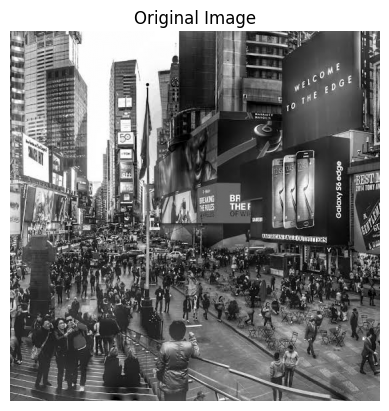

In [ ]:
plt.imshow(img, cmap='gray')
plt.title('Original Image')
plt.axis('off')

In [ ]:
def gaussian_noise(image, mean=0, sigma=25):
    gaussian_noise = np.random.normal(mean, sigma, image.shape).astype(np.float32)
    noisy_image = image.astype(np.float32) + gaussian_noise
    noisy_image = np.clip(noisy_image, 0, 255).astype(np.uint8)

    return noisy_image

(np.float64(-0.5), np.float64(553.5), np.float64(553.5), np.float64(-0.5))

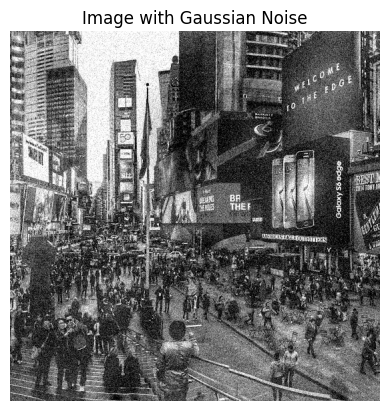

In [ ]:
noisy_image = gaussian_noise(img, mean=0, sigma=25)
plt.imshow(noisy_image, cmap='gray')
plt.title('Image with Gaussian Noise')
plt.axis('off')

(np.float64(-0.5), np.float64(553.5), np.float64(553.5), np.float64(-0.5))

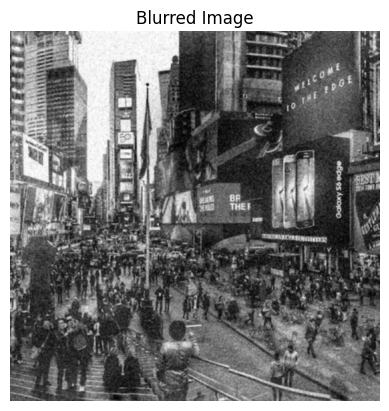

In [ ]:
kernel = 1 /16 * np.array([[1, 2, 1], [2, 4, 2], [1, 2, 1]])
blurred_image = cv.filter2D(noisy_image, -1, kernel)
plt.imshow(blurred_image, cmap='gray')
plt.title('Blurred Image')
plt.axis('off')

(np.float64(-0.5), np.float64(553.5), np.float64(553.5), np.float64(-0.5))

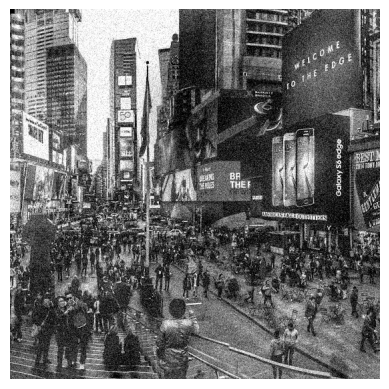

In [ ]:
# gaussian filter using the formula
def gaussian_filter(image, ksize = 7, sigma=1):
    k = ksize // 2
    
    # Create a Gaussian kernel
    x, y = np.mgrid[-k:k+1, -k:k+1]
    kernel = (1 / (2 * np.pi * sigma**2)) * np.exp(-(x**2 + y**2) / (2 * sigma**2))
    kernel /= np.sum(kernel)
    padded = np.pad( image, ((k, k), (k, k)), mode='edge')
    
    out_h, out_w = image.shape
    filtered = np.zeros((out_h, out_w), dtype=np.float32)
    
    # Convolution
    for i in range(out_h):
        for j in range(out_w):
            window = padded[i:i + ksize, j:j + ksize]
            filtered[i, j] = np.sum(window * kernel)
            
    return np.clip(filtered, 0, 255).astype(np.uint8)

In [ ]:
filtered_image = gaussian_filter(noisy_image, ksize=7, sigma=1)
plt.imshow(filtered_image, cmap='gray')
plt.axis("off")
plt.show()